In [1]:
#load the data
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from gensim.models import Word2Vec
import gensim.downloader as api

train = pd.read_csv("data/processed/train.csv")
test  = pd.read_csv("data/processed/test.csv")

X_train, y_train = train["text"], train["label"]
X_test,  y_test  = test["text"],  test["label"]
print(train.shape, test.shape)

(3659, 4) (915, 4)


In [2]:
#helper: score a model the same way as 01 and 02 (macro-averaged)
results, preds = [], {}

def evaluate(name, y_pred):
    preds[name] = y_pred
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    results.append({"model": name, "accuracy": accuracy_score(y_test, y_pred),
                    "precision": p, "recall": r, "f1": f1})
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3))

In [3]:
#Logistic Regression + TF-IDF
#second version uses class_weight="balanced" so the 35% negative class counts as much as the positive class
for name, cw in [("LR + TF-IDF", None), ("LR + TF-IDF (balanced)", "balanced")]:
    model = Pipeline([("vec", TfidfVectorizer()),
                      ("lr", LogisticRegression(max_iter=1000, class_weight=cw))])
    model.fit(X_train, y_train)
    evaluate(name, model.predict(X_test))
    if cw is None:
        tfidf_model = model

=== LR + TF-IDF ===
              precision    recall  f1-score   support

    negative      0.787     0.600     0.681       320
    positive      0.809     0.913     0.858       595

    accuracy                          0.803       915
   macro avg      0.798     0.756     0.769       915
weighted avg      0.801     0.803     0.796       915

=== LR + TF-IDF (balanced) ===
              precision    recall  f1-score   support

    negative      0.698     0.809     0.750       320
    positive      0.888     0.812     0.848       595

    accuracy                          0.811       915
   macro avg      0.793     0.811     0.799       915
weighted avg      0.822     0.811     0.814       915



In [4]:
#word embeddings: a sentence is the average of its word vectors
def tokenize(s):
    return re.findall(r"[a-z']+", s)

train_tok = [tokenize(s) for s in X_train]
test_tok  = [tokenize(s) for s in X_test]

def sentence_vectors(token_lists, kv):
    out = []
    for toks in token_lists:
        vecs = [kv[w] for w in toks if w in kv]
        out.append(np.mean(vecs, axis=0) if vecs else np.zeros(kv.vector_size))
    return np.array(out)

#Word2Vec trained only on our training sentences (100 dims)
w2v = Word2Vec(train_tok, vector_size=100, window=5, min_count=2,
               workers=1, seed=42, epochs=20)
print("Word2Vec vocabulary:", len(w2v.wv))

#GloVe pre-trained on Wikipedia + Gigaword (400k words, 100 dims, ~128MB download the first time)
glove = api.load("glove-wiki-gigaword-100")
print("GloVe vocabulary:", len(glove))

Word2Vec vocabulary: 2787


GloVe vocabulary: 400000


In [5]:
#Logistic Regression + embeddings
for name, kv in [("LR + Word2Vec", w2v.wv), ("LR + GloVe", glove)]:
    Xtr, Xte = sentence_vectors(train_tok, kv), sentence_vectors(test_tok, kv)
    model = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    evaluate(name, model.predict(Xte))

results_df = pd.DataFrame(results).round(3)
results_df

=== LR + Word2Vec ===
              precision    recall  f1-score   support

    negative      0.670     0.481     0.560       320
    positive      0.758     0.872     0.811       595

    accuracy                          0.736       915
   macro avg      0.714     0.677     0.685       915
weighted avg      0.727     0.736     0.723       915



=== LR + GloVe ===
              precision    recall  f1-score   support

    negative      0.725     0.600     0.656       320
    positive      0.803     0.877     0.839       595

    accuracy                          0.780       915
   macro avg      0.764     0.739     0.747       915
weighted avg      0.776     0.780     0.775       915



,model,accuracy,precision,recall,f1
0,LR + TF-IDF,0.803,0.798,0.756,0.769
1,LR + TF-IDF (balanced),0.811,0.793,0.811,0.799
2,LR + Word2Vec,0.736,0.714,0.677,0.685
3,LR + GloVe,0.780,0.764,0.739,0.747


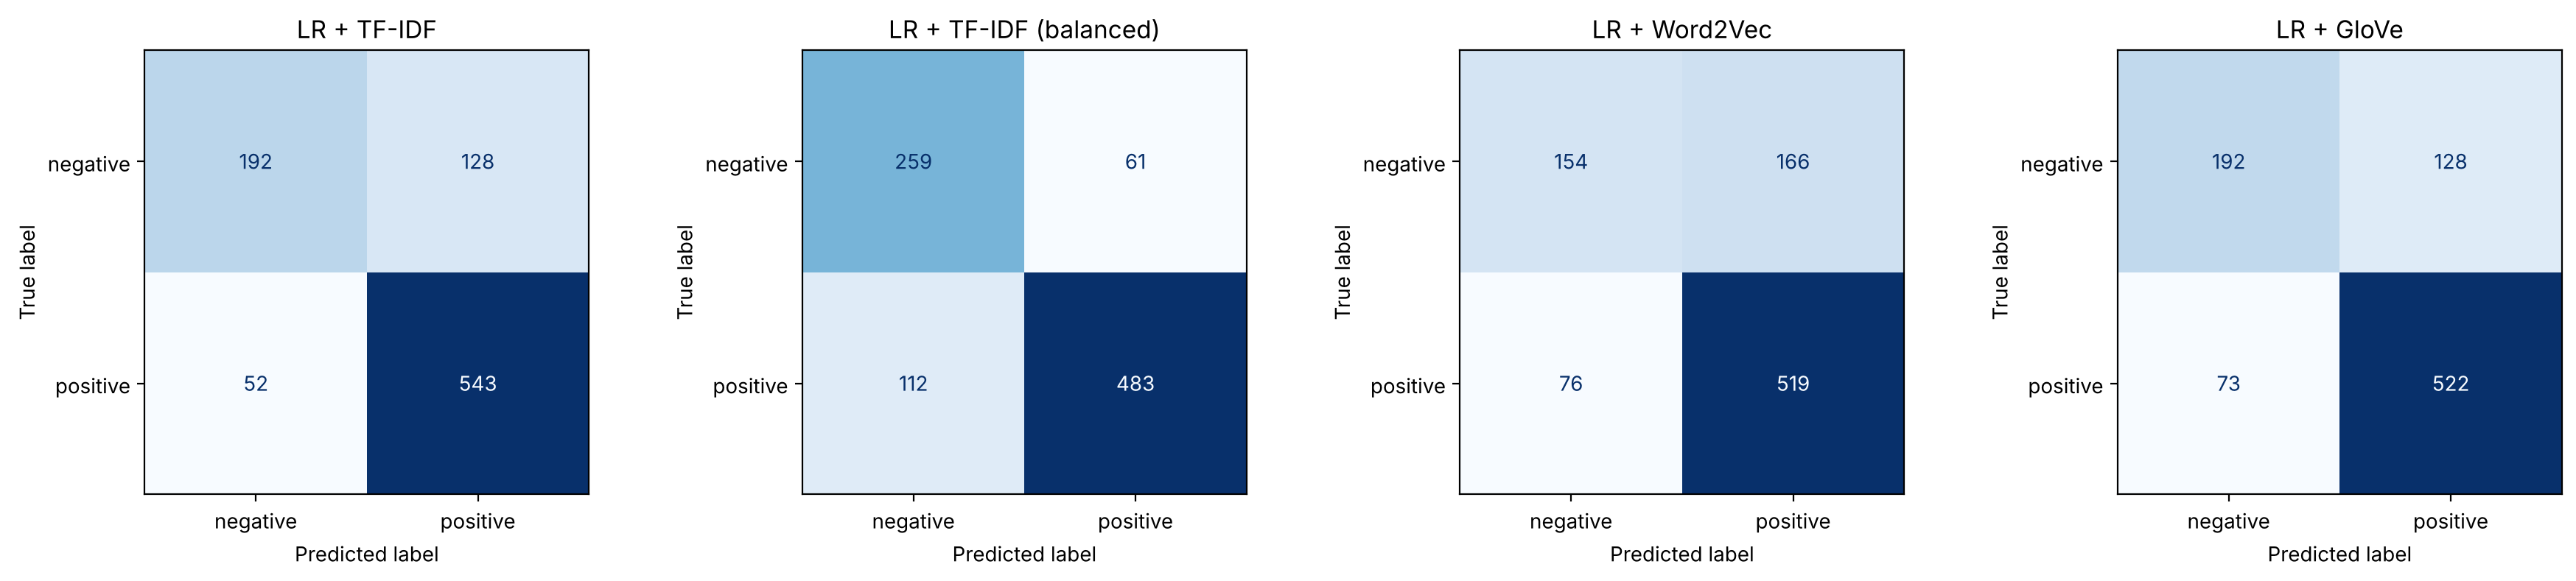

In [6]:
#confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/fig3_logreg_confusion.png", dpi=150)
plt.show()

In [7]:
#which words the TF-IDF model learned
vec, lr = tfidf_model.named_steps["vec"], tfidf_model.named_steps["lr"]
words = np.array(vec.get_feature_names_out())
coef = lr.coef_[0]          #positive coefficient -> pushes toward "positive"
print("Most positive words:", ", ".join(words[np.argsort(coef)[-15:][::-1]]))
print("Most negative words:", ", ".join(words[np.argsort(coef)[:15]]))

Most positive words: great, easy, good, and, excellent, love, nice, camera, well, price, best, very, features, use, perfect
Most negative words: not, only, does, poor, unfortunately, bad, after, useless, when, flaw, problem, slow, jack, them, software


In [8]:
#look at mistakes, then save results
mistakes = test.assign(pred=preds["LR + TF-IDF (balanced)"])
mistakes = mistakes[mistakes["label"] != mistakes["pred"]]
print(f"{len(mistakes)} wrong out of {len(test)}")
display(mistakes[["text", "label", "pred"]].head(10))

results_df.to_csv("results_03.csv", index=False)

173 wrong out of 915


,text,label,pred
3,"secondly, all info can be sent to a computer a...",positive,negative
4,"since then, i have not found one major problem...",positive,negative
5,the linksys technical support site has nothing...,negative,positive
9,"i do not count this as a negative, however, be...",positive,negative
21,"i 'm not easily impressed by electronics , ten...",positive,negative
24,i found that low light situations combined wit...,negative,positive
27,this netbook is closer to the notebook powers ...,positive,negative
39,even during the firmware updates my roommates ...,positive,negative
50,"i rarely get drawn in by mass-commercialism, b...",positive,negative
56,1 ) quite bulky ( it 's about the same size as...,negative,positive
